<a href="https://colab.research.google.com/github/Raji150273/Python-Level-4-sprint-1/blob/main/Python_Visualisation_Project_Corsea_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Python Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

sns.set_style("whitegrid")

# Mount Google Drive to access your files
drive.mount('/content/drive')

# Load data
df = pd.read_csv("/content/drive/MyDrive/coursea_data.csv")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0,course_title,course_organization,course_Certificate_type,course_rating,course_difficulty,course_students_enrolled
0,134,(ISC)² Systems Security Certified Practitioner...,(ISC)²,SPECIALIZATION,4.7,Beginner,5.3k
1,743,A Crash Course in Causality: Inferring Causal...,University of Pennsylvania,COURSE,4.7,Intermediate,17k
2,874,A Crash Course in Data Science,Johns Hopkins University,COURSE,4.5,Mixed,130k
3,413,A Law Student's Toolkit,Yale University,COURSE,4.7,Mixed,91k
4,635,A Life of Happiness and Fulfillment,Indian School of Business,COURSE,4.8,Mixed,320k


In [ ]:

# CHECK DATA SET INFORMATION

df.info()
df.shape
df.describe(include='all')



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                891 non-null    int64  
 1   course_title              891 non-null    object 
 2   course_organization       891 non-null    object 
 3   course_Certificate_type   891 non-null    object 
 4   course_rating             891 non-null    float64
 5   course_difficulty         891 non-null    object 
 6   course_students_enrolled  891 non-null    object 
dtypes: float64(1), int64(1), object(5)
memory usage: 48.9+ KB


,Unnamed: 0,course_title,course_organization,course_Certificate_type,course_rating,course_difficulty,course_students_enrolled
count,891.000000,891,891,891,891.000000,891,891
unique,NaN,888,154,3,NaN,4,205
top,NaN,Developing Your Musicianship,University of Pennsylvania,COURSE,NaN,Beginner,120k
freq,NaN,2,59,582,NaN,487,22
mean,445.000000,NaN,NaN,NaN,4.677329,NaN,NaN
std,257.353842,NaN,NaN,NaN,0.162225,NaN,NaN
min,0.000000,NaN,NaN,NaN,3.300000,NaN,NaN
25%,222.500000,NaN,NaN,NaN,4.600000,NaN,NaN
50%,445.000000,NaN,NaN,NaN,4.700000,NaN,NaN
75%,667.500000,NaN,NaN,NaN,4.800000,NaN,NaN


In [ ]:
 # MISSING VALUE
df.isnull().sum()

,0
Unnamed: 0,0
course_title,0
course_organization,0
course_Certificate_type,0
course_rating,0
course_difficulty,0
course_students_enrolled,0


In [ ]:
# Convert Student Enrollment to Numeric
import pandas as pd
import os


def convert_enrollment(x):
    x = str(x).lower()

    if 'k' in x:
        return float(x.replace('k', '')) * 1000

    if 'm' in x:
        return float(x.replace('m', '')) * 1000000

    return float(x)

df['students_enrolled'] = df['course_students_enrolled'].apply(convert_enrollment)
df[['course_students_enrolled', 'students_enrolled']].head()

,course_students_enrolled,students_enrolled
0,5.3k,5300.0
1,17k,17000.0
2,130k,130000.0
3,91k,91000.0
4,320k,320000.0


In [ ]:
# Exploratory Data Analysis (EDA)

print("Number of courses:", len(df))
print("Number of organizations:", df['course_organization'].nunique())



Number of courses: 891
Number of organizations: 154


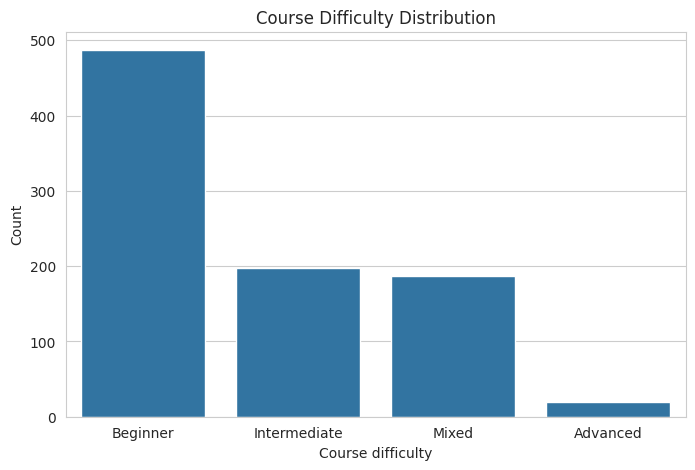

In [ ]:
## Course Difficulty Distribution
##Visualisation

plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='course_difficulty',
              order=df['course_difficulty'].value_counts().index)

plt.title('Course Difficulty Distribution')
plt.xlabel('Course difficulty')
plt.ylabel('Count')
plt.show()

In [ ]:
# Beginner courses dominate the platform.
# Advanced courses represent a much smaller proportion.
# Coursera is primarily targeted at entry-level learners.

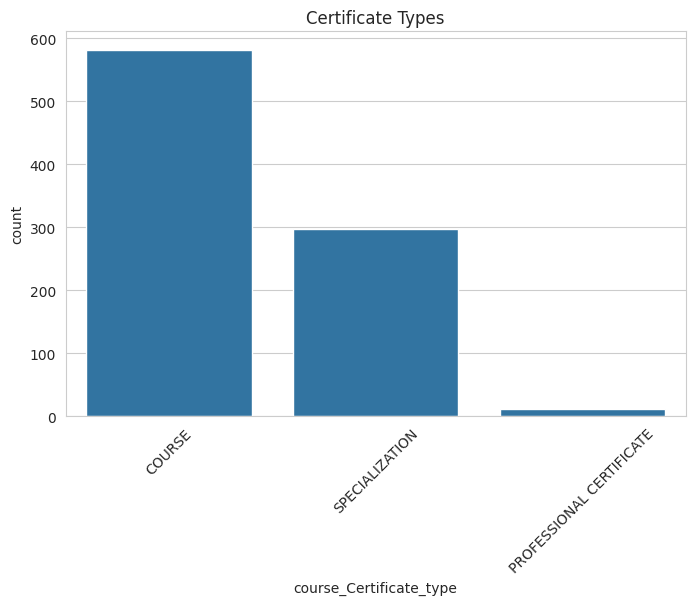

In [ ]:
# Certificate Type Distribution
# Python

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='course_Certificate_type',
    order=df['course_Certificate_type'].value_counts().index
)

plt.xticks(rotation=45)
plt.title('Certificate Types')
plt.show()


## Most offerings are individual courses, followed by specializations and professional certificates.

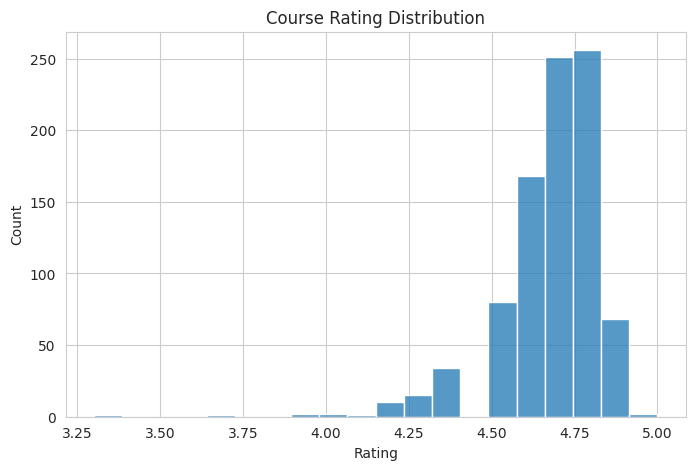

In [ ]:
## Rating Distribution


plt.figure(figsize=(8,5))
sns.histplot(df['course_rating'], bins=20)

plt.title('Course Rating Distribution')
plt.xlabel('Rating')
plt.show()


##Ratings are heavily concentrated between 4.5 and 4.9.
 ##Most courses receive very positive feedback from learners.

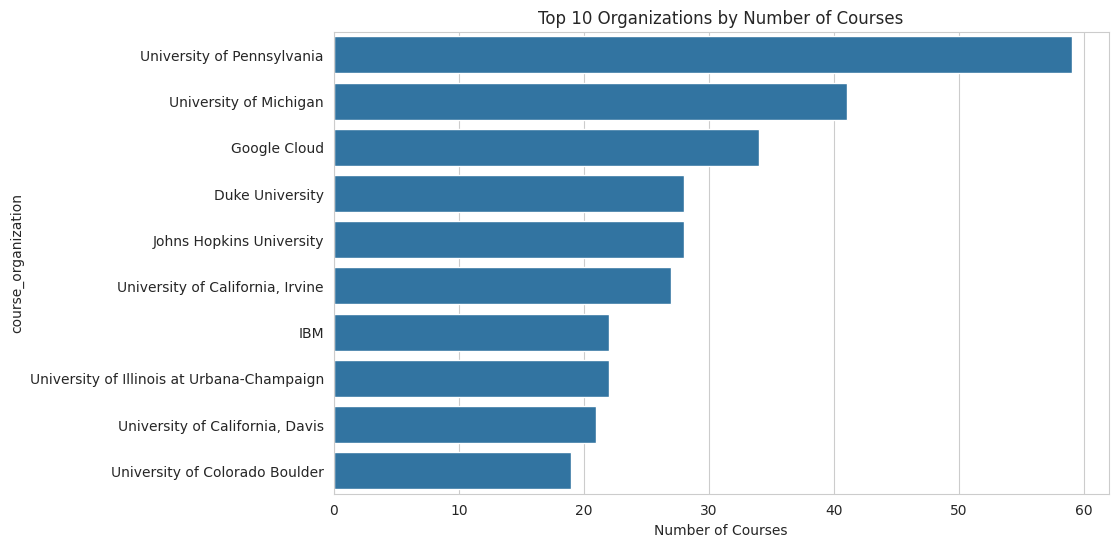

In [ ]:
## Top 10 Organizations by Number of Courses

top_orgs = df['course_organization'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(
    x=top_orgs.values,
    y=top_orgs.index
)

plt.title('Top 10 Organizations by Number of Courses')
plt.xlabel('Number of Courses')
plt.show()


# Organizations such as: University of Pennsylvania, University of Michigan, Google Cloud, Johns Hopkins University appear frequently within the dataset.

In [ ]:
## Highest Rated Courses
top_rated = df.sort_values(
    'course_rating',
    ascending=False
)[['course_title','course_organization','course_rating']]

top_rated.head(10)


## Several courses have perfect ratings (5.0), although many of these have relatively small enrolment numbers compared to Coursera's most popular offerings.

,course_title,course_organization,course_rating
251,El Abogado del Futuro: Legaltech y la Transfor...,Universidad Austral,5.0
432,Infectious Disease Modelling,Imperial College London,5.0
82,Become a CBRS Certified Professional Installer...,Google - Spectrum Sharing,4.9
472,Introduction to Breast Cancer,Yale University,4.9
626,Neural Networks and Deep Learning,deeplearning.ai,4.9
754,Stories of Infection,Stanford University,4.9
103,Build a Modern Computer from First Principles:...,Hebrew University of Jerusalem,4.9
102,Bugs 101: Insect-Human Interactions,University of Alberta,4.9
460,International Women's Health and Human Rights,Stanford University,4.9
147,Compassionate Leadership Through Service Learn...,University of Colorado Boulder,4.9


In [ ]:
## Most Popular Courses

top_popular = df.sort_values(
    'students_enrolled',
    ascending=False
)

top_popular[
    ['course_title',
     'course_organization',
     'students_enrolled']
].head(10)

## Key Findings about the courses:
# Machine Learning (Stanford University)
#The Science of Well-Being (Yale University)
# Python for Everybody(University of Michigan)
#These courses attract hundreds of thousands or even millions of learners.

,course_title,course_organization,students_enrolled
564,Machine Learning,Stanford University,3200000.0
815,The Science of Well-Being,Yale University,2500000.0
688,Python for Everybody,University of Michigan,1500000.0
674,Programming for Everybody (Getting Started wit...,University of Michigan,1300000.0
196,Data Science,Johns Hopkins University,830000.0
129,Career Success,"University of California, Irvine",790000.0
261,English for Career Development,University of Pennsylvania,760000.0
765,Successful Negotiation: Essential Strategies a...,University of Michigan,750000.0
199,Data Science: Foundations using R,Johns Hopkins University,740000.0
211,Deep Learning,deeplearning.ai,690000.0


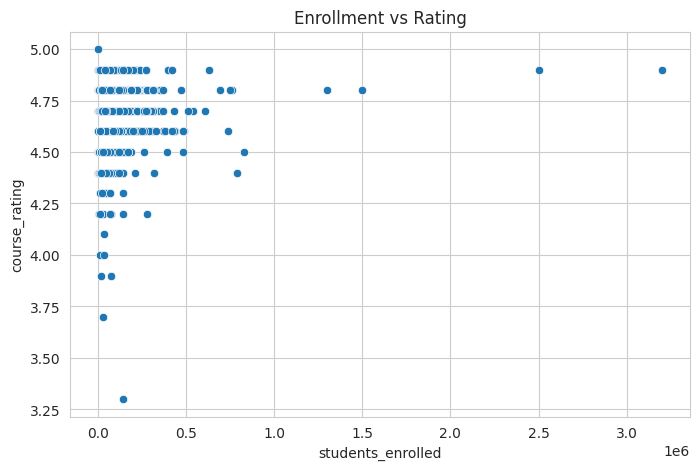

In [ ]:
## Rating vs Student Enrollment

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='students_enrolled',
    y='course_rating'
)

plt.title('Enrollment vs Rating')
plt.show()

#High enrolment does not necessarily result in higher ratings.
# Most courses cluster between 4.5 and 5.0 ratings.
# Popularity and satisfaction are only weakly related.

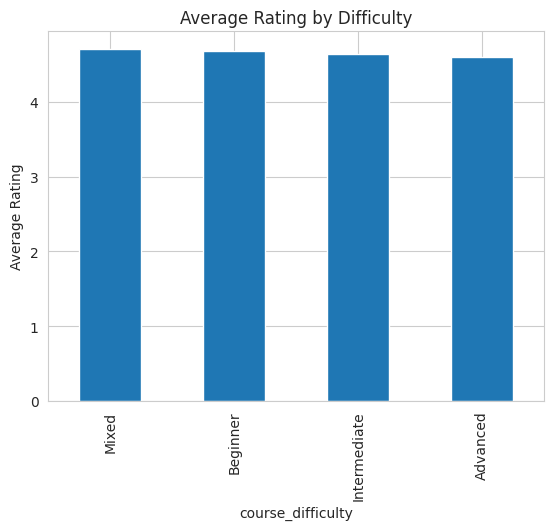

In [ ]:
## Average Rating by Difficulty
avg_rating = df.groupby(
    'course_difficulty'
)['course_rating'].mean().sort_values(ascending=False)

avg_rating.plot(kind='bar')

plt.title('Average Rating by Difficulty')
plt.ylabel('Average Rating')
plt.show()

# Ratings may be relatively consistent across all difficulty levels, indicating learner satisfaction is generally high regardless of complexity.

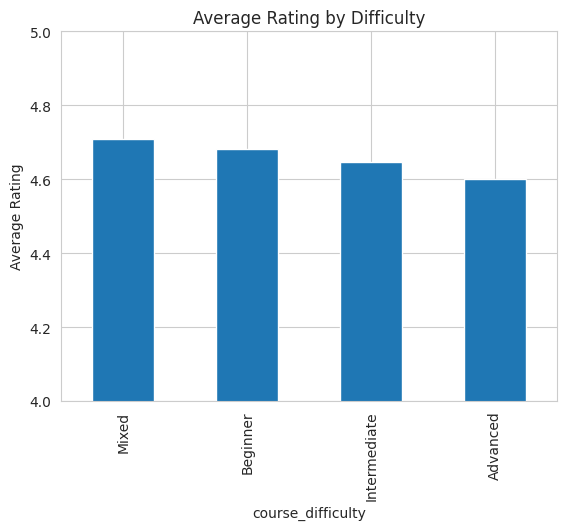

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Safely calculate avg_rating if it's not currently defined in memory
try:
    avg_rating
except NameError:
    avg_rating = df.groupby('course_difficulty')['course_rating'].mean().sort_values(ascending=False)

avg_rating.plot(kind='bar')

plt.title('Average Rating by Difficulty')
plt.ylabel('Average Rating')
plt.ylim(4.0, 5.0)   # Focus on the rating range
plt.show()

#The graph shows all difficulty levels achieved ratings above 4.5, indicating that learners are generally
# satisfied with courses regardless of difficulty.
#All difficulty levels are highly rated, and course difficulty appears to have only a minor/little effect on learner ratings.

/tmp/ipykernel_1266/1533506893.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


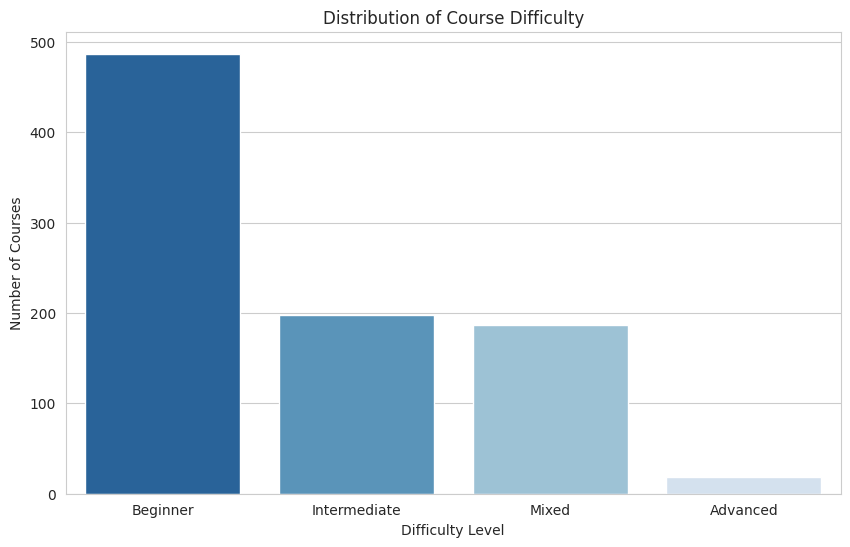

In [ ]:
##Visualisation Quality (jusy to get it to high level) Good practices
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x='course_difficulty',
    palette='Blues_r'
)

plt.title('Distribution of Course Difficulty')
plt.xlabel('Difficulty Level')
plt.ylabel('Number of Courses')
plt.show()

In [ ]:
count = df['course_difficulty'].value_counts()

percentages = df['course_difficulty'].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    'Count': count,
    'Percentage': percentages.round(2)
})

print(summary)

#This suggests that higher no of learners 54% are at the beginner level and low no of learners 2% are at advances level.

                   Count  Percentage
course_difficulty                   
Beginner             487       54.66
Intermediate         198       22.22
Mixed                187       20.99
Advanced              19        2.13


In [ ]:
corr_matrix = df[['course_rating', 'students_enrolled']].corr()
print(corr_matrix)

## the results below shows 0.07109. A correlation of 0.071 is very close to zero. This means there is almost no relationship between course ratings and student enrolment.
##Highly rated courses are not necessarily the most popular.


                   course_rating  students_enrolled
course_rating            1.00000            0.07109
students_enrolled        0.07109            1.00000


In [ ]:

## Beginner courses are more popular than advanced courses. Beginner courses dominate both course volume and enrolment numbers


##Some highly rated courses have large enrolments, but many top-rated courses have relatively few learners.It seems to be no relationship between the rating and enrolmemt.


## University providers dominate the platform.

# Universities account for a large proportion of courses and many of them are most popular programmes.